In [ ]:
"""
Ensemble learning is a machine learning approach that combines predictions from multiple models to produce a stronger or more reliable result than one model alone. Combines Weak learners to form a strong one.
4 Pilars => Bagging, Boosting, Voting, Stacking

1) Bagging:trains models independently in parallel and combines their results (for example, Random Forest).

2) Boosting: trains models in sequence, with each new model focusing on earlier mistakes, so trained in a smarter way and making predictions by voting (EX: AdaBoost, XGBoost)
"""


'\nEnsemble learning is a machine learning approach that combines predictions from multiple models to produce a stronger or more reliable result than one model alone. Combines Weak learners to form a strong one.\n2 Options => Bagging or Boosting\n\n1) Bagging:trains models independently in parallel and combines their results (for example, Random Forest).\n\n2) Boosting: trains models in sequence, with each new model focusing on earlier mistakes, so trained in a smarter way and making predictions by voting (EX: AdaBoost, XGBoost)\n'

In [133]:
"""
AdaBoost (Adaptive Boosting) is a popular boosting algorithm that combines multiple weak classifiers to create a strong classifier. It works by assigning weights to each training instance, giving more importance to misclassified instances in subsequent iterations. The final prediction is made by combining the predictions of all weak classifiers, typically through a weighted majority vote.

Using very simple learners (1-depth decision tree) to build a strong learner

Steps:

Train the first learner
Increase the weight of the data samples that learner predicts incorrectly
Decrease the weight of the data samples that learner predicts correctly
Weights are changed using "Odd Ratio" (rescaling factor)
Train another learner using the modified dataset
Repeat steps 2,3,4 for all other learners
Make the prediction using the weighted voting based on the performance of each learner

"""

'\nAdaBoost (Adaptive Boosting) is a popular boosting algorithm that combines multiple weak classifiers to create a strong classifier. It works by assigning weights to each training instance, giving more importance to misclassified instances in subsequent iterations. The final prediction is made by combining the predictions of all weak classifiers, typically through a weighted majority vote.\n\nUsing very simple learners (1-depth decision tree) to build a strong learner\n\nSteps:\n\nTrain the first learner\nIncrease the weight of the data samples that learner predicts incorrectly\nDecrease the weight of the data samples that learner predicts correctly\nWeights are changed using "Odd Ratio" (rescaling factor)\nTrain another learner using the modified dataset\nRepeat steps 2,3,4 for all other learners\nMake the prediction using the weighted voting based on the performance of each learner\n\n'

In [134]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score ,ConfusionMatrixDisplay

In [135]:
data = pd.read_csv("XGBOOST_Data.csv")
data

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,...,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,...,2,2,2,2,4,2,4,0,20.0,satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25971,25971,78463,Male,disloyal Customer,34,Business travel,Business,526,3,3,...,4,3,2,4,4,5,4,0,0.0,neutral or dissatisfied
25972,25972,71167,Male,Loyal Customer,23,Business travel,Business,646,4,4,...,4,4,5,5,5,5,4,0,0.0,satisfied
25973,25973,37675,Female,Loyal Customer,17,Personal Travel,Eco,828,2,5,...,2,4,3,4,5,4,2,0,0.0,neutral or dissatisfied
25974,25974,90086,Male,Loyal Customer,14,Business travel,Business,1127,3,3,...,4,3,2,5,4,5,4,0,0.0,satisfied


In [136]:
print(data.head())

   Unnamed: 0     id  Gender      Customer Type  Age   Type of Travel  \
0           0  19556  Female     Loyal Customer   52  Business travel   
1           1  90035  Female     Loyal Customer   36  Business travel   
2           2  12360    Male  disloyal Customer   20  Business travel   
3           3  77959    Male     Loyal Customer   44  Business travel   
4           4  36875  Female     Loyal Customer   49  Business travel   

      Class  Flight Distance  Inflight wifi service  \
0       Eco              160                      5   
1  Business             2863                      1   
2       Eco              192                      2   
3  Business             3377                      0   
4       Eco             1182                      2   

   Departure/Arrival time convenient  ...  Inflight entertainment  \
0                                  4  ...                       5   
1                                  1  ...                       4   
2                      

In [137]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 25976 entries, 0 to 25975
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         25976 non-null  int64  
 1   id                                 25976 non-null  int64  
 2   Gender                             25976 non-null  str    
 3   Customer Type                      25976 non-null  str    
 4   Age                                25976 non-null  int64  
 5   Type of Travel                     25976 non-null  str    
 6   Class                              25976 non-null  str    
 7   Flight Distance                    25976 non-null  int64  
 8   Inflight wifi service              25976 non-null  int64  
 9   Departure/Arrival time convenient  25976 non-null  int64  
 10  Ease of Online booking             25976 non-null  int64  
 11  Gate location                      25976 non-null  int64  
 12  F

Gender
Female    13172
Male      12804
Name: count, dtype: int64
Customer Type
Loyal Customer       21177
disloyal Customer     4799
Name: count, dtype: int64
Type of Travel
Business travel    18038
Personal Travel     7938
Name: count, dtype: int64
Class
Business    12495
Eco         11564
Eco Plus     1917
Name: count, dtype: int64
satisfaction
neutral or dissatisfied    14573
satisfied                  11403
Name: count, dtype: int64


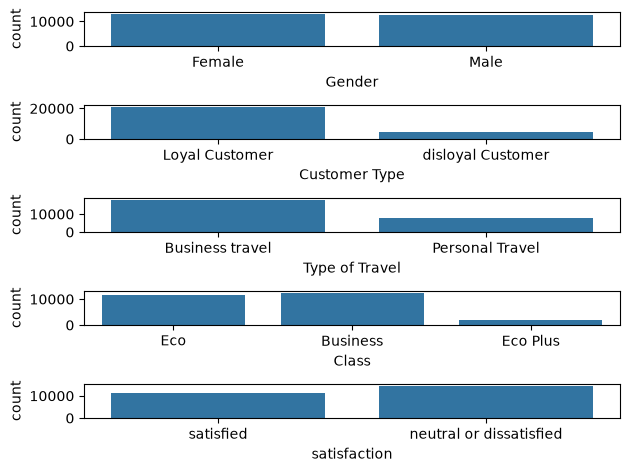

In [138]:
non_numeric = ["Gender", "Customer Type", "Type of Travel", "Class", "satisfaction"]

figure, ax = plt.subplots(5,1)
x=0
for i in non_numeric:
  print(data[i].value_counts())
  sns.countplot(data=data, x=i, ax=ax[x])
  x+=1
  
plt.tight_layout()

In [139]:
print(data.columns)
data.drop(columns= ['Unnamed: 0', 'id'], inplace=True)

Index(['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel',
       'Class', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='str')


In [140]:
print(data.isnull().sum())

Gender                                0
Customer Type                         0
Age                                   0
Type of Travel                        0
Class                                 0
Flight Distance                       0
Inflight wifi service                 0
Departure/Arrival time convenient     0
Ease of Online booking                0
Gate location                         0
Food and drink                        0
Online boarding                       0
Seat comfort                          0
Inflight entertainment                0
On-board service                      0
Leg room service                      0
Baggage handling                      0
Checkin service                       0
Inflight service                      0
Cleanliness                           0
Departure Delay in Minutes            0
Arrival Delay in Minutes             83
satisfaction                          0
dtype: int64


In [141]:
print(data["Arrival Delay in Minutes"])
print(data["Arrival Delay in Minutes"].describe())
# filling with median
data["Arrival Delay in Minutes"] = data["Arrival Delay in Minutes"].fillna(data["Arrival Delay in Minutes"].median())

0        44.0
1         0.0
2         0.0
3         6.0
4        20.0
         ... 
25971     0.0
25972     0.0
25973     0.0
25974     0.0
25975     0.0
Name: Arrival Delay in Minutes, Length: 25976, dtype: float64
count    25893.000000
mean        14.740857
std         37.517539
min          0.000000
25%          0.000000
50%          0.000000
75%         13.000000
max       1115.000000
Name: Arrival Delay in Minutes, dtype: float64


In [142]:
print(data.isnull().sum()) # 0

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64


In [143]:
features = data.drop(columns="satisfaction")
target = data["satisfaction"]

In [144]:
Xtrain, Xtest, ytrain, ytest = train_test_split(features, target, test_size=0.2, random_state=42)
# Encoding non-numeric Features data
encoder = LabelEncoder()
Xtrain_encoded = Xtrain.copy()
Xtest_encoded = Xtest.copy()
non_numeric_features = non_numeric.copy()
non_numeric_features.remove("satisfaction")
for i in non_numeric_features:
  Xtrain_encoded[i] = encoder.fit_transform(Xtrain_encoded[i])
  Xtest_encoded[i] = encoder.transform(Xtest_encoded[i])
  

In [145]:
print(Xtrain_encoded.info())
print(Xtest_encoded.info())
# NO more categorical data

<class 'pandas.DataFrame'>
Index: 20780 entries, 10324 to 23654
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             20780 non-null  int64  
 1   Customer Type                      20780 non-null  int64  
 2   Age                                20780 non-null  int64  
 3   Type of Travel                     20780 non-null  int64  
 4   Class                              20780 non-null  int64  
 5   Flight Distance                    20780 non-null  int64  
 6   Inflight wifi service              20780 non-null  int64  
 7   Departure/Arrival time convenient  20780 non-null  int64  
 8   Ease of Online booking             20780 non-null  int64  
 9   Gate location                      20780 non-null  int64  
 10  Food and drink                     20780 non-null  int64  
 11  Online boarding                    20780 non-null  int64  
 12  Se

In [146]:
# Scaling the encoded data, to remove outliers / bias effect
scalar = StandardScaler()

Xtrain_scaled = scalar.fit_transform(Xtrain_encoded)
Xtest_scaled = scalar.fit_transform(Xtest_encoded)

In [147]:
# Encoding target
ytrain_encoded = encoder.fit_transform(ytrain)
ytest_encoded = encoder.transform(ytest)
print(ytrain_encoded)
print(ytest_encoded)

[1 0 1 ... 1 0 0]
[0 1 0 ... 1 1 1]


In [148]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
# Bagging choice ( Random Forest)
random_forest_classifier = RandomForestClassifier(n_estimators=100, random_state=1)
random_forest_classifier.fit(Xtrain_scaled, ytrain_encoded)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [149]:
ypred = random_forest_classifier.predict(Xtest_scaled)

print(classification_report(ytest_encoded, ypred))
print(accuracy_score(ytest_encoded, ypred))

              precision    recall  f1-score   support

           0       0.95      0.97      0.96      2945
           1       0.95      0.94      0.94      2251

    accuracy                           0.95      5196
   macro avg       0.95      0.95      0.95      5196
weighted avg       0.95      0.95      0.95      5196

0.9524634334103156


In [150]:
# Boosting Choice (AdaBoost)

ada_classifier = AdaBoostClassifier(n_estimators=100)
ada_classifier.fit(Xtrain_scaled, ytrain_encoded)

ada_ypred = ada_classifier.predict(Xtest_scaled)

print(classification_report(ytest_encoded, ada_ypred))
print(accuracy_score(ytest_encoded, ada_ypred))

              precision    recall  f1-score   support

           0       0.93      0.92      0.92      2945
           1       0.90      0.91      0.90      2251

    accuracy                           0.91      5196
   macro avg       0.91      0.91      0.91      5196
weighted avg       0.92      0.91      0.91      5196

0.9149345650500385


In [154]:
# Boosting choice 2nd (XGBoost)

from xgboost import XGBClassifier

xgboost_classifier = XGBClassifier(n_estimators=300)
xgboost_classifier.fit(Xtrain_scaled, ytrain_encoded)

xgb_ypred = ada_classifier.predict(Xtest_scaled)

print(classification_report(ytest_encoded, xgb_ypred))
print(accuracy_score(ytest_encoded, xgb_ypred))

              precision    recall  f1-score   support

           0       0.93      0.92      0.92      2945
           1       0.90      0.91      0.90      2251

    accuracy                           0.91      5196
   macro avg       0.91      0.91      0.91      5196
weighted avg       0.92      0.91      0.91      5196

0.9149345650500385
